# Application poussée — modèles champion/challenger, SHAP et monitoring CBPE

Ce notebook complète les scripts `application_poussee/models/train.py`,
`application_poussee/explainability/run_shap.py` et
`application_poussee/monitoring/run_monitoring.py` : même logique, mêmes
hyperparamètres, mêmes features, mais exécutée ici dans un document unique
avec les graphiques affichés directement dans les cellules — dans le même
esprit que `exploration_drift_detection.ipynb` pour la première partie du
mémoire.

**À exécuter depuis le dossier `application_poussee/`** (ouvrir ce notebook
depuis Jupyter en étant positionné dans ce dossier, pour que les chemins
relatifs vers `../data/` et vers les sous-dossiers `models/`,
`explainability/`, `monitoring/` fonctionnent).

Rappel méthodologique (cf. `application-poussee-modele-shap-monitoring.md`,
section 2) : le champion et le challenger entraînés ici sont des modèles
**indépendants** du modèle d'origine surveillé dans le corps principal du
mémoire (corrélation de prédictions ≈ 0,50). Les résultats SHAP et de
monitoring qui suivent décrivent le comportement de *ces* modèles, pas une
explication directe du modèle d'origine.


In [1]:
%matplotlib inline
import sys
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import nannyml as nml
import numpy as np
import pandas as pd
import shap
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Résolution robuste de la racine application_poussee/, que le notebook
# soit lancé depuis ce dossier (cas normal) ou depuis la racine du repo.
CANDIDATES = [Path.cwd(), Path.cwd() / "application_poussee"]
ROOT = next((c for c in CANDIDATES if (c / "models" / "features.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Impossible de localiser application_poussee/ (dossier contenant models/features.py). "
        "Lance Jupyter depuis le dossier application_poussee/."
    )
sys.path.insert(0, str(ROOT))
from models.features import build_feature_matrix, feature_columns, TARGET_COL  # noqa: E402

DATA_DIR = ROOT.parent / "data"
ARTIFACTS = ROOT / "models" / "artifacts"
ARTIFACTS.mkdir(parents=True, exist_ok=True)
SHAP_OUT = ROOT / "reports" / "shap"
SHAP_OUT.mkdir(parents=True, exist_ok=True)
MONITORING_OUT = ROOT / "reports" / "monitoring"
MONITORING_OUT.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
COLOR_REF = "#2a78d6"
COLOR_ANA = "#eb6834"

print("ROOT:", ROOT)
print("DATA_DIR:", DATA_DIR)


ROOT: C:\Users\sokpe\fraude-drift-monitoring\application_poussee
DATA_DIR: C:\Users\sokpe\fraude-drift-monitoring\data


## 1. Chargement des données et construction des features

Les cinq variables disponibles sont transformées en matrice de features
(encodage one-hot de `transaction_type`, imputation des valeurs manquantes
par une modalité `MISSING` dédiée), de façon identique entre les deux
périodes et cohérente avec le reste du mémoire.

In [2]:
reference = pd.read_csv(DATA_DIR / "reference.csv", parse_dates=["timestamp"])
analysis = pd.read_csv(DATA_DIR / "analysis.csv", parse_dates=["timestamp"])

X = build_feature_matrix(reference)
y = reference[TARGET_COL].astype(int)
cols = feature_columns()

X_train, X_holdout, y_train, y_holdout = train_test_split(
    X[cols], y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape[0]} lignes | Holdout: {X_holdout.shape[0]} lignes")
print(f"Taux de fraude train: {y_train.mean():.4f} | holdout: {y_holdout.mean():.4f}")


Train: 40165 lignes | Holdout: 10042 lignes
Taux de fraude train: 0.4998 | holdout: 0.4997


## 2. Entraînement du champion (LightGBM)

Petite recherche sur 3 configurations d'hyperparamètres, sélection sur la
PR-AUC de validation (split interne train/validation), puis réentraînement
du meilleur modèle sur l'ensemble de `X_train`.

In [3]:
def evaluate(y_true, y_proba, threshold=0.5) -> dict:
    y_pred = (y_proba >= threshold).astype(int)
    return {
        "precision": float(precision_score(y_true, y_pred)),
        "recall": float(recall_score(y_true, y_pred)),
        "f1": float(f1_score(y_true, y_pred)),
        "roc_auc": float(roc_auc_score(y_true, y_proba)),
        "pr_auc": float(average_precision_score(y_true, y_proba)),
    }


X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE
)

param_grid = [
    {"num_leaves": 31, "learning_rate": 0.05, "n_estimators": 400, "min_child_samples": 20},
    {"num_leaves": 63, "learning_rate": 0.03, "n_estimators": 600, "min_child_samples": 30},
    {"num_leaves": 15, "learning_rate": 0.08, "n_estimators": 300, "min_child_samples": 15},
]
best_model, best_pr_auc, best_params = None, -1.0, None
for params in param_grid:
    model = lgb.LGBMClassifier(objective="binary", random_state=RANDOM_STATE, verbosity=-1, **params)
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_val, y_val)],
        eval_metric="average_precision",
        callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)],
    )
    val_proba = model.predict_proba(X_val)[:, 1]
    val_pr_auc = average_precision_score(y_val, val_proba)
    print(f"  config {params} -> PR-AUC val = {val_pr_auc:.4f}")
    if val_pr_auc > best_pr_auc:
        best_model, best_pr_auc, best_params = model, val_pr_auc, params

champion = lgb.LGBMClassifier(objective="binary", random_state=RANDOM_STATE, verbosity=-1, **best_params)
champion.fit(X_train, y_train)
champion_holdout_proba = champion.predict_proba(X_holdout[cols])[:, 1]
champion_metrics = evaluate(y_holdout, champion_holdout_proba)
print("\nChampion (LightGBM) - holdout:", champion_metrics)
print("best_params:", best_params)


  config {'num_leaves': 31, 'learning_rate': 0.05, 'n_estimators': 400, 'min_child_samples': 20} -> PR-AUC val = 0.8081
  config {'num_leaves': 63, 'learning_rate': 0.03, 'n_estimators': 600, 'min_child_samples': 30} -> PR-AUC val = 0.8067
  config {'num_leaves': 15, 'learning_rate': 0.08, 'n_estimators': 300, 'min_child_samples': 15} -> PR-AUC val = 0.8079

Champion (LightGBM) - holdout: {'precision': 0.7880945599544289, 'recall': 0.5514149063371862, 'f1': 0.6488451166608044, 'roc_auc': 0.7435827755748097, 'pr_auc': 0.7926255302096451}
best_params: {'num_leaves': 31, 'learning_rate': 0.05, 'n_estimators': 400, 'min_child_samples': 20}


## 3. Entraînement du challenger (régression logistique)

Modèle simple et interprétable, entraîné sur les mêmes features
standardisées, servant de point de comparaison au champion.

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_holdout_scaled = scaler.transform(X_holdout[cols])

challenger = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
challenger.fit(X_train_scaled, y_train)
challenger_holdout_proba = challenger.predict_proba(X_holdout_scaled)[:, 1]
challenger_metrics = evaluate(y_holdout, challenger_holdout_proba)
print("Challenger (LogReg) - holdout:", challenger_metrics)

comparison_df = pd.DataFrame({"Champion (LightGBM)": champion_metrics, "Challenger (LogReg)": challenger_metrics}).T
comparison_df


Challenger (LogReg) - holdout: {'precision': 0.7372703412073491, 'recall': 0.5597847748106816, 'f1': 0.6363842319891255, 'roc_auc': 0.7252220826680003, 'pr_auc': 0.7784739706803401}


,precision,recall,f1,roc_auc,pr_auc
Champion (LightGBM),0.788095,0.551415,0.648845,0.743583,0.792626
Challenger (LogReg),0.737270,0.559785,0.636384,0.725222,0.778474


## 4. Sauvegarde des artefacts et scoring de `analysis.csv`

Les deux modèles sont sauvegardés sur disque (réutilisés par la section
SHAP et par le monitoring CBPE plus bas), puis utilisés pour scorer
`analysis.csv` (simulation de la production). La corrélation avec
`predicted_fraud_proba` (colonne déjà présente dans les données, issue du
modèle d'origine) sert de vérification de cohérence.

In [5]:
import json

joblib.dump(champion, ARTIFACTS / "champion_lightgbm.joblib")
joblib.dump({"model": challenger, "scaler": scaler}, ARTIFACTS / "challenger_logreg.joblib")

metrics = {
    "champion": {"params": best_params, **champion_metrics},
    "challenger": challenger_metrics,
    "n_train": int(X_train.shape[0]),
    "n_holdout": int(X_holdout.shape[0]),
    "fraud_rate_train": float(y_train.mean()),
    "fraud_rate_holdout": float(y_holdout.mean()),
}
with open(ARTIFACTS / "training_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

X_analysis = build_feature_matrix(analysis)[cols]
analysis_scored = analysis.copy()
analysis_scored["champion_proba"] = champion.predict_proba(X_analysis)[:, 1]
analysis_scored["challenger_proba"] = challenger.predict_proba(scaler.transform(X_analysis))[:, 1]
analysis_scored.to_csv(ARTIFACTS / "analysis_scored.csv", index=False)

corr_champion = analysis_scored["champion_proba"].corr(analysis_scored["predicted_fraud_proba"])
corr_challenger = analysis_scored["challenger_proba"].corr(analysis_scored["predicted_fraud_proba"])
print(f"Correlation champion vs predicted_fraud_proba d'origine : {corr_champion:.4f}")
print(f"Correlation challenger vs predicted_fraud_proba d'origine : {corr_challenger:.4f}")
print("\nArtefacts écrits dans", ARTIFACTS)


Correlation champion vs predicted_fraud_proba d'origine : 0.4978
Correlation challenger vs predicted_fraud_proba d'origine : 0.4713

Artefacts écrits dans C:\Users\sokpe\fraude-drift-monitoring\application_poussee\models\artifacts


## 5. Explicabilité SHAP (référence vs analyse)

Valeurs SHAP calculées sur le champion (TreeExplainer), séparément sur un
échantillon de la période de référence et un échantillon de la période
d'analyse, pour vérifier si l'importance des variables reste stable dans
le temps — réponse à la demande d'explicabilité de M. Mihoubi (Workshop 2,
section 5).

In [6]:
X_ref = build_feature_matrix(reference)[cols]
X_ana = build_feature_matrix(analysis)[cols]

rng = np.random.RandomState(42)
ref_sample = X_ref.sample(n=5000, random_state=rng)
ana_sample = X_ana.sample(n=5000, random_state=rng)

explainer = shap.TreeExplainer(champion)
sv_ref = explainer.shap_values(ref_sample)
sv_ana = explainer.shap_values(ana_sample)
if isinstance(sv_ref, list):
    sv_ref = sv_ref[1]
    sv_ana = sv_ana[1]

imp_ref = pd.Series(np.abs(sv_ref).mean(axis=0), index=cols).sort_values(ascending=False)
imp_ana = pd.Series(np.abs(sv_ana).mean(axis=0), index=cols).sort_values(ascending=False)

imp_df = pd.DataFrame({"reference": imp_ref, "analyse": imp_ana.reindex(imp_ref.index)})
imp_df = imp_df.sort_values("reference", ascending=False)
imp_df.to_csv(SHAP_OUT / "shap_importance_reference_vs_analyse.csv")
imp_df


C:\Users\sokpe\AppData\Local\anaconda3\envs\drift-monitoring\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
C:\Users\sokpe\AppData\Local\anaconda3\envs\drift-monitoring\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


,reference,analyse
user_tenure_months,1.188380,1.180903
transaction_amount,0.188670,0.194216
time_since_login_min,0.080340,0.078768
transaction_type_PAYMENT,0.014284,0.014512
transaction_type_CASH-IN,0.013681,0.014360
is_first_transaction,0.013624,0.013153
transaction_type_CASH-OUT,0.011337,0.011852
transaction_type_TRANSFER,0.007112,0.007883
transaction_type_MISSING,0.004658,0.004356


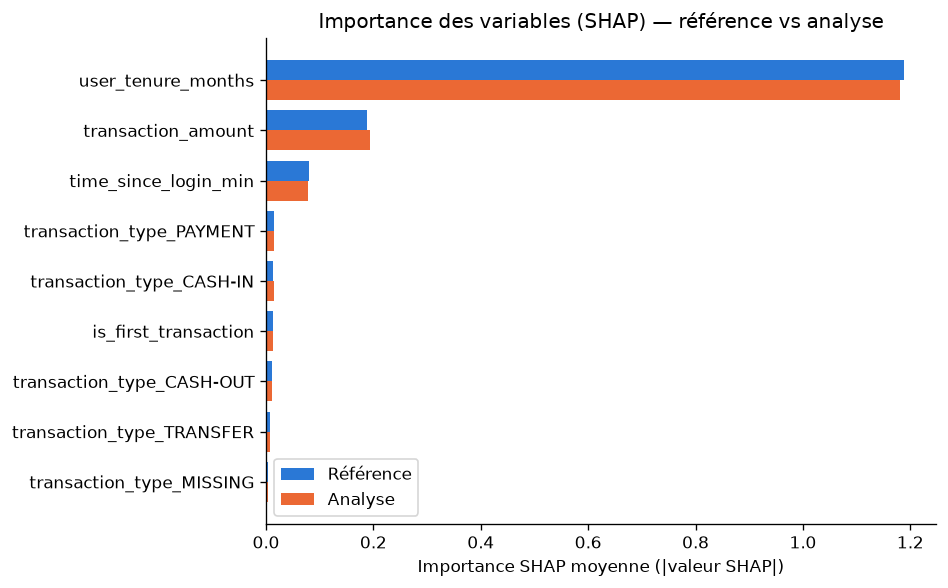

In [7]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=120)
y_pos = np.arange(len(imp_df))
ax.barh(y_pos - 0.2, imp_df["reference"], height=0.4, color=COLOR_REF, label="Référence")
ax.barh(y_pos + 0.2, imp_df["analyse"], height=0.4, color=COLOR_ANA, label="Analyse")
ax.set_yticks(y_pos)
ax.set_yticklabels(imp_df.index)
ax.invert_yaxis()
ax.set_xlabel("Importance SHAP moyenne (|valeur SHAP|)")
ax.set_title("Importance des variables (SHAP) — référence vs analyse")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(SHAP_OUT / "shap_importance_reference_vs_analyse.png")
plt.show()


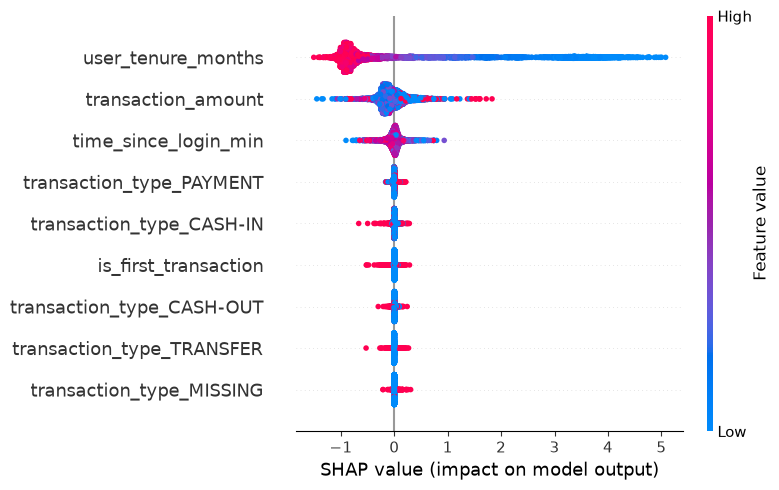

In [8]:
shap.summary_plot(sv_ref, ref_sample, show=False)
plt.gcf().set_size_inches(8, 5)
plt.tight_layout()
plt.savefig(SHAP_OUT / "shap_summary_reference.png")
plt.show()


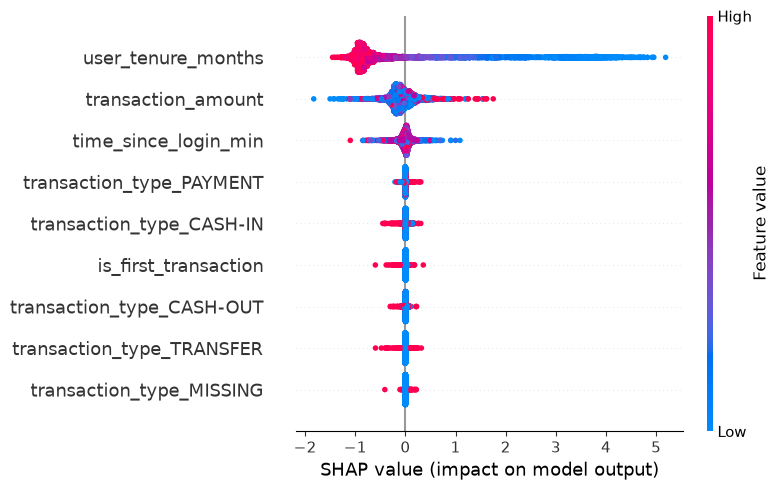

In [9]:
shap.summary_plot(sv_ana, ana_sample, show=False)
plt.gcf().set_size_inches(8, 5)
plt.tight_layout()
plt.savefig(SHAP_OUT / "shap_summary_analyse.png")
plt.show()


Zoom sur `time_since_login_min`, variable au cœur du diagnostic de drift
établi dans la première partie du mémoire (`analyse-comparative-outils-drift.md`) :

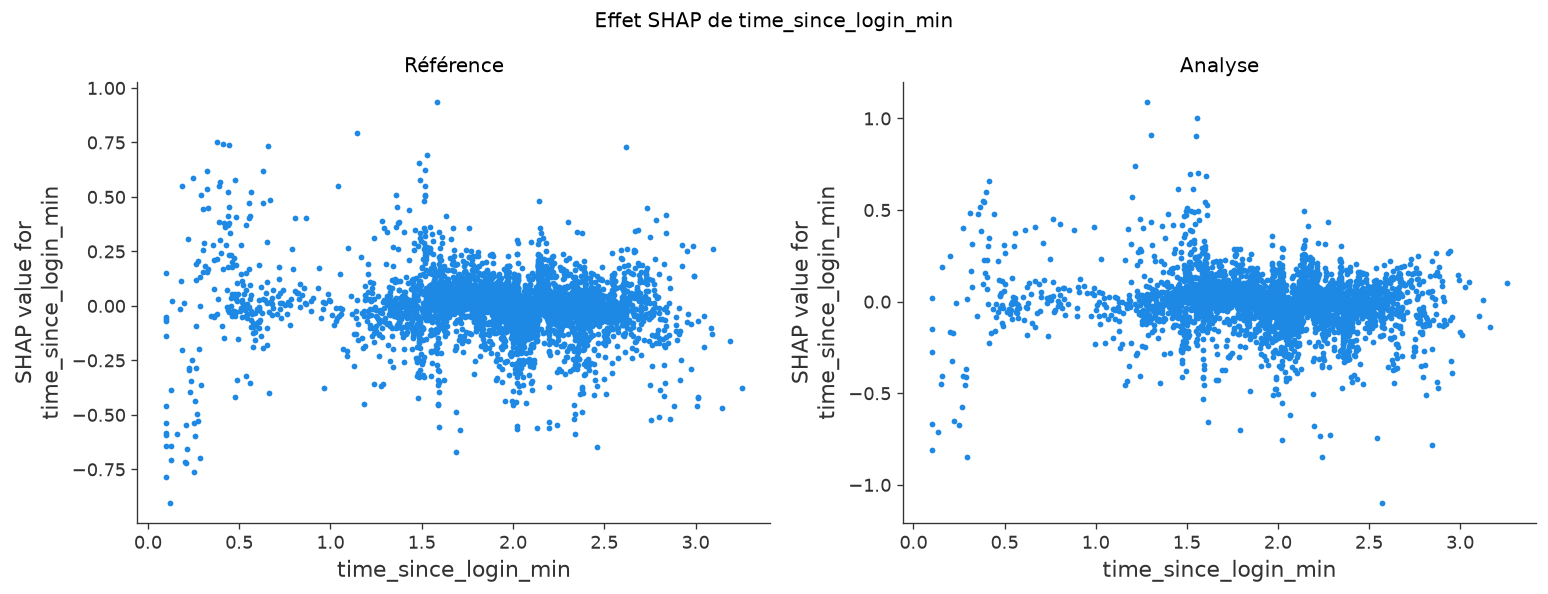

Rapports SHAP écrits dans C:\Users\sokpe\fraude-drift-monitoring\application_poussee\reports\shap


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=120)
plt.sca(axes[0])
shap.dependence_plot("time_since_login_min", sv_ref, ref_sample, show=False, interaction_index=None, dot_size=12, ax=axes[0])
axes[0].set_title("Référence")
plt.sca(axes[1])
shap.dependence_plot("time_since_login_min", sv_ana, ana_sample, show=False, interaction_index=None, dot_size=12, ax=axes[1])
axes[1].set_title("Analyse")
fig.suptitle("Effet SHAP de time_since_login_min")
fig.tight_layout()
fig.savefig(SHAP_OUT / "shap_dependence_time_since_login_min_reference_analyse.png")
plt.show()

summary = {
    "top_feature_reference": str(imp_ref.index[0]),
    "top_feature_analyse": str(imp_ana.index[0]),
    "importance_reference": imp_ref.to_dict(),
    "importance_analyse": imp_ana.to_dict(),
}
with open(SHAP_OUT / "shap_summary.json", "w") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
print("Rapports SHAP écrits dans", SHAP_OUT)


## 6. Monitoring CBPE du champion — estimé vs réel, par mois

Même protocole CBPE (NannyML) que celui déjà utilisé sur le modèle
d'origine, calibré ici sur le holdout de référence (pour éviter toute
fuite des données d'entraînement) et confronté à la performance **réelle**
mensuelle — calculable car `is_fraud` est disponible dans `analysis.csv`.

In [11]:
holdout_ts = reference.loc[X_holdout.index, "timestamp"]

ref_df = pd.DataFrame({
    "timestamp": holdout_ts.values,
    "y_pred_proba": champion.predict_proba(X_holdout)[:, 1],
    "is_fraud": y_holdout.values,
})
ref_df["y_pred"] = (ref_df["y_pred_proba"] >= 0.5).astype(int)
ref_df = ref_df.sort_values("timestamp").reset_index(drop=True)

ana_df = analysis_scored[["timestamp", "champion_proba", "is_fraud"]].rename(columns={"champion_proba": "y_pred_proba"})
ana_df["y_pred"] = (ana_df["y_pred_proba"] >= 0.5).astype(int)
ana_df = ana_df.sort_values("timestamp").reset_index(drop=True)

estimator = nml.CBPE(
    problem_type="classification_binary",
    y_pred_proba="y_pred_proba", y_pred="y_pred", y_true="is_fraud",
    metrics=["roc_auc", "precision", "recall", "f1"],
    chunk_period="M", timestamp_column_name="timestamp",
)
estimator.fit(ref_df)
est_df = estimator.estimate(ana_df).to_df()
est_df = est_df[est_df[("chunk", "period")] == "analysis"].copy()
est_df["month"] = pd.to_datetime(est_df[("chunk", "start_date")]).dt.strftime("%Y-%m")

ana_df["month"] = pd.to_datetime(ana_df["timestamp"]).dt.to_period("M").astype(str)
real_rows = []
for month, grp in ana_df.groupby("month"):
    real_rows.append({
        "month": month,
        "precision": precision_score(grp["is_fraud"], grp["y_pred"]),
        "recall": recall_score(grp["is_fraud"], grp["y_pred"]),
        "f1": f1_score(grp["is_fraud"], grp["y_pred"]),
        "roc_auc": roc_auc_score(grp["is_fraud"], grp["y_pred_proba"]),
    })
real_df = pd.DataFrame(real_rows)

comparison = real_df.copy()
for metric in ["roc_auc", "precision", "recall", "f1"]:
    comparison[f"{metric}_estime_cbpe"] = est_df[(metric, "value")].values
    comparison[f"{metric}_alerte_cbpe"] = est_df[(metric, "alert")].values
    comparison = comparison.rename(columns={metric: f"{metric}_reel"})
comparison.to_csv(MONITORING_OUT / "comparaison_cbpe_vs_reel_champion.csv", index=False)
comparison


,month,precision_reel,recall_reel,f1_reel,roc_auc_reel,roc_auc_estime_cbpe,roc_auc_alerte_cbpe,precision_estime_cbpe,precision_alerte_cbpe,recall_estime_cbpe,recall_alerte_cbpe,f1_estime_cbpe,f1_alerte_cbpe
0,2018-11,0.800436,0.575461,0.669555,0.755048,0.770191,False,0.801068,False,0.580789,False,0.673371,False
1,2018-12,0.784161,0.557052,0.651378,0.750222,0.762803,False,0.799187,False,0.560005,False,0.658551,False
2,2019-01,0.788908,0.559390,0.654614,0.752654,0.761004,False,0.798883,False,0.555240,False,0.655143,False
3,2019-02,0.780000,0.544503,0.641316,0.730872,0.760815,False,0.796976,False,0.553680,False,0.653415,False
4,2019-03,0.804043,0.556982,0.658088,0.746400,0.763318,False,0.802129,False,0.558789,False,0.658704,False
5,2019-04,0.783679,0.488691,0.601990,0.705757,0.749385,False,0.802033,False,0.517394,False,0.629011,False
6,2019-05,0.788071,0.482517,0.598554,0.712190,0.751011,False,0.808040,False,0.514965,False,0.629041,False
7,2019-06,0.803040,0.490117,0.608717,0.715422,0.751327,False,0.813552,False,0.512336,False,0.628729,False


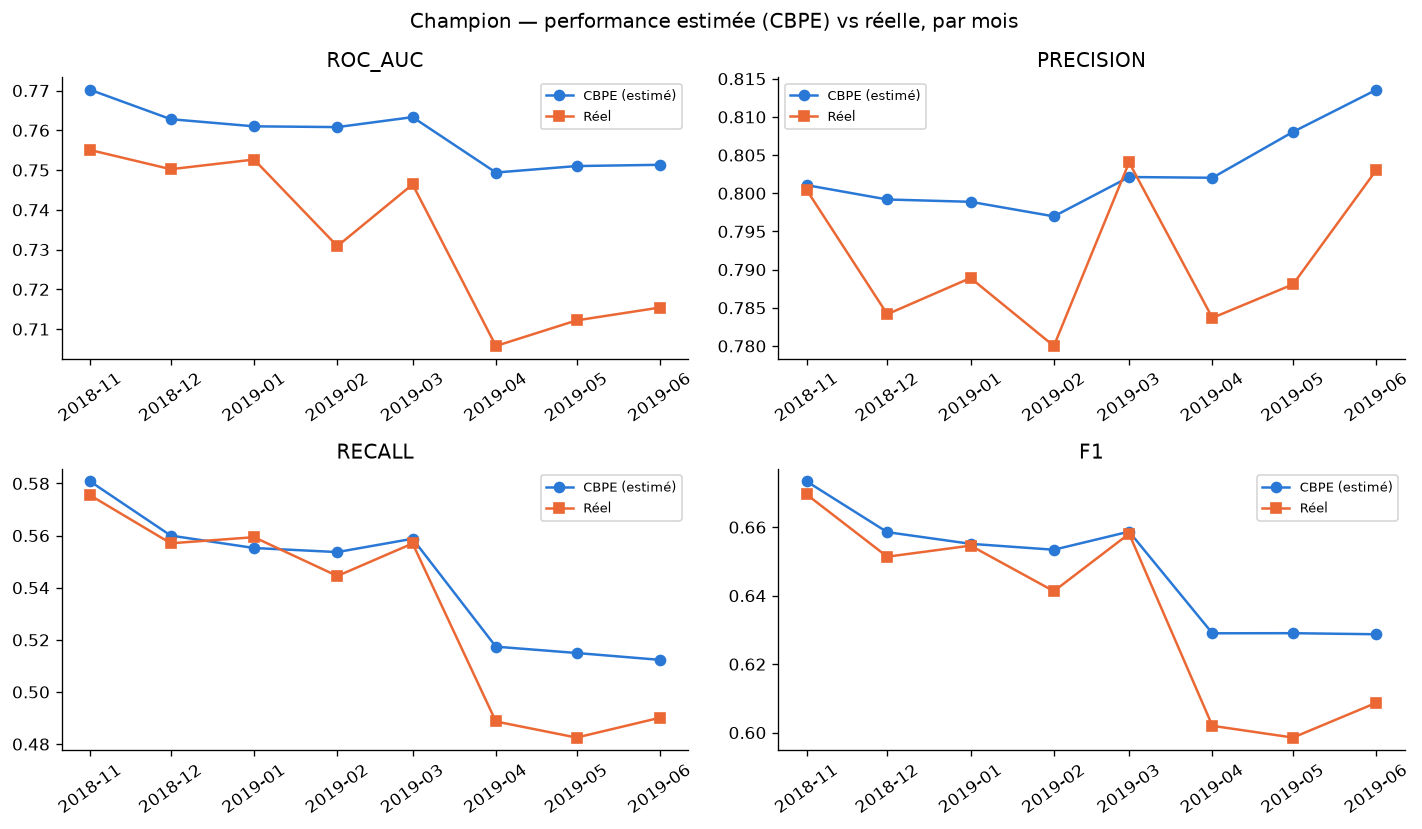


Nombre total d'alertes CBPE déclenchées (4 métriques x 8 mois) : 0
Rapports écrits dans C:\Users\sokpe\fraude-drift-monitoring\application_poussee\reports\monitoring


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), dpi=120)
axes = axes.ravel()
x = pd.to_datetime(comparison["month"])
for ax, metric in zip(axes, ["roc_auc", "precision", "recall", "f1"]):
    ax.plot(x, comparison[f"{metric}_estime_cbpe"], marker="o", color=COLOR_REF, label="CBPE (estimé)")
    ax.plot(x, comparison[f"{metric}_reel"], marker="s", color=COLOR_ANA, label="Réel")
    ax.set_title(metric.upper())
    ax.legend(fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="x", rotation=35)
fig.suptitle("Champion — performance estimée (CBPE) vs réelle, par mois")
fig.tight_layout()
fig.savefig(MONITORING_OUT / "cbpe_vs_reel_champion.png")
plt.show()

n_alerts = sum(comparison[f"{m}_alerte_cbpe"].sum() for m in ["roc_auc", "precision", "recall", "f1"])
print(f"\nNombre total d'alertes CBPE déclenchées (4 métriques x 8 mois) : {n_alerts}")
print("Rapports écrits dans", MONITORING_OUT)


## 7. Synthèse

- Le champion (LightGBM) devance le challenger (régression logistique) sur
  la quasi-totalité des métriques de holdout.
- `user_tenure_months` domine très largement l'importance SHAP, de façon
  stable entre référence et analyse — comportement propre à ce champion,
  à ne pas confondre avec le diagnostic de dérive de `time_since_login_min`
  établi sur le modèle d'origine (section 2 du document d'accompagnement).
- La performance réelle du champion se dégrade à partir d'avril 2019, dans
  la même fenêtre temporelle que le modèle d'origine — un indice de
  changement structurel des données, pas une preuve causale partagée entre
  les deux modèles (entraînés indépendamment, corrélation ≈ 0,50).
- CBPE suit la tendance de dégradation mais la sous-estime, et ne déclenche
  aucune alerte sur la période malgré une baisse réelle visible — constat
  qui alimente directement la recommandation d'une règle de tendance
  complémentaire au seuil statique (cf.
  `architecture-monitoring-alertes-retraining.md`).

Pour le détail narratif complet (tableaux, limites, comparaison avec le
dépôt de référence sentinel-fraud-mlops), voir
`application-poussee-modele-shap-monitoring.md`.
